In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:

import sys
import torch
import transformers
import tokenizers

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("GPU:", torch.cuda.get_device_name(0))


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Transformers: 5.18.0
Tokenizers: 0.23.2
GPU: Tesla T4


In [ ]:

import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

MODEL_NAME = "microsoft/trocr-base-handwritten"

processor = TrOCRProcessor.from_pretrained(MODEL_NAME)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_NAME)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device).eval()

print("Model loaded successfully!")
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.17k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model loaded successfully!
Device: cuda
GPU: Tesla T4


In [ ]:

from datasets import load_dataset
from IPython.display import display
import torch

# Load one public handwriting example
dataset = load_dataset(
    "Teklia/IAM-line",
    split="test",
    streaming=True
)

sample = next(iter(dataset))
print("Available fields:", sample.keys())


README.md:   0%|          | 0.00/2.14k [00:00<?, ?B/s]

Available fields: dict_keys(['image', 'text'])


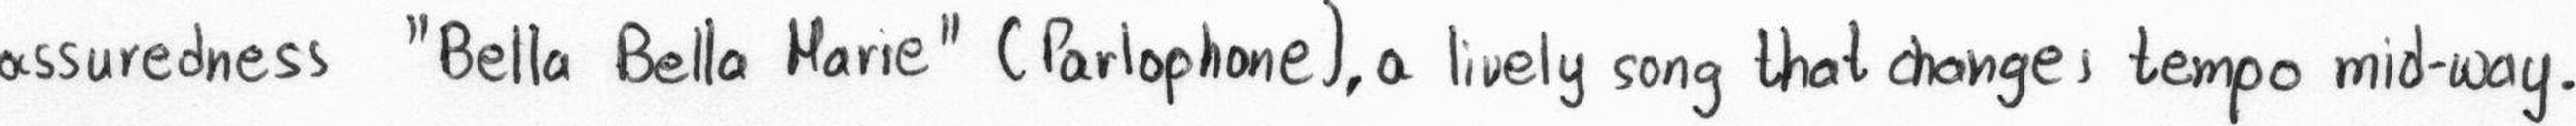

ACTUAL TEXT:    assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
PREDICTED TEXT: assuredness " Bella Bella Marie " ( Bishopsome ) a lively song that changes tempo midway


In [ ]:

from IPython.display import display
import torch

# Get the image and its correct text
image = sample["image"].convert("RGB")
actual_text = sample["text"]

# Display the handwriting image
display(image)

# Convert the image into a format TrOCR understands
pixel_values = processor(
    images=image,
    return_tensors="pt"
).pixel_values.to(device)

# Ask TrOCR to read the handwriting
with torch.inference_mode():
    generated_ids = model.generate(
        pixel_values,
        max_new_tokens=128
    )

# Convert the model's output into readable text
predicted_text = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True
)[0]

print("ACTUAL TEXT:   ", actual_text)
print("PREDICTED TEXT:", predicted_text)


In [ ]:

import time
import numpy as np
import torch

# Warm-up: the first runs may be slower
with torch.inference_mode():
    for _ in range(5):
        model.generate(pixel_values, max_new_tokens=128)

if device == "cuda":
    torch.cuda.synchronize()

# Measure 30 predictions
latencies = []

for _ in range(30):
    if device == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        model.generate(pixel_values, max_new_tokens=128)

    if device == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    latencies.append(elapsed)

print("BASELINE INFERENCE RESULTS")
print(f"Mean latency: {np.mean(latencies):.3f} seconds")
print(f"P50 latency:  {np.percentile(latencies, 50):.3f} seconds")
print(f"P99 latency:  {np.percentile(latencies, 99):.3f} seconds")


BASELINE INFERENCE RESULTS
Mean latency: 0.323 seconds
P50 latency:  0.320 seconds
P99 latency:  0.350 seconds


In [ ]:

import copy
import time
import numpy as np
import torch

# Keep the original FP32 model unchanged
model_fp16 = copy.deepcopy(model).half().eval()

# Convert the input image tensor to FP16
pixel_values_fp16 = pixel_values.half()

# Warm-up
with torch.inference_mode():
    for _ in range(5):
        model_fp16.generate(
            pixel_values_fp16,
            max_new_tokens=128
        )

torch.cuda.synchronize()

# Benchmark FP16
fp16_latencies = []

for _ in range(30):
    torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        model_fp16.generate(
            pixel_values_fp16,
            max_new_tokens=128
        )

    torch.cuda.synchronize()
    fp16_latencies.append(time.perf_counter() - start)

print("FP16 RESULTS")
print(f"Mean latency: {np.mean(fp16_latencies):.3f} seconds")
print(f"P50 latency:  {np.percentile(fp16_latencies, 50):.3f} seconds")
print(f"P99 latency:  {np.percentile(fp16_latencies, 99):.3f} seconds")


FP16 RESULTS
Mean latency: 0.260 seconds
P50 latency:  0.260 seconds
P99 latency:  0.301 seconds


In [ ]:

with torch.inference_mode():
    fp16_ids = model_fp16.generate(
        pixel_values_fp16,
        max_new_tokens=128
    )

fp16_prediction = processor.batch_decode(
    fp16_ids,
    skip_special_tokens=True
)[0]

print("ACTUAL TEXT:   ", actual_text)
print("FP32 PREDICTION:", predicted_text)
print("FP16 PREDICTION:", fp16_prediction)
print("FP32 == FP16:", predicted_text == fp16_prediction)


ACTUAL TEXT:    assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
FP32 PREDICTION: assuredness " Bella Bella Marie " ( Bishopsome ) a lively song that changes tempo midway
FP16 PREDICTION: assuredness " Bella Bella Marie " ( Bishopsome ) a lively song that changes tempo midway
FP32 == FP16: True


In [ ]:

from datasets import load_dataset

# Load the test split again as a fresh stream
test_dataset = load_dataset(
    "Teklia/IAM-line",
    split="test",
    streaming=True
)

# Collect up to 100 usable examples
samples = []

for item in test_dataset:
    if item.get("image") is not None and item.get("text"):
        samples.append(item)
    if len(samples) == 100:
        break

print("Number of test images:", len(samples))
print("First actual text:", samples[0]["text"])


Number of test images: 100
First actual text: assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .


In [ ]:

import time
import numpy as np
import torch

# Character/word edit distance
def edit_distance(a, b):
    previous = list(range(len(b) + 1))

    for i, x in enumerate(a, 1):
        current = [i]
        for j, y in enumerate(b, 1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j - 1] + (x != y)
            ))
        previous = current

    return previous[-1]


def calculate_metrics(references, predictions):
    char_errors = word_errors = 0
    total_chars = total_words = 0

    for ref, pred in zip(references, predictions):
        ref, pred = ref.strip(), pred.strip()

        char_errors += edit_distance(ref, pred)
        word_errors += edit_distance(ref.split(), pred.split())
        total_chars += len(ref)
        total_words += len(ref.split())

    return (
        100 * char_errors / max(total_chars, 1),
        100 * word_errors / max(total_words, 1)
    )


def evaluate_model(test_samples, current_model, use_fp16=False):
    references = []
    predictions = []
    latencies = []

    # Warm-up the model
    first_image = test_samples[0]["image"].convert("RGB")
    first_pixels = processor(
        images=first_image, return_tensors="pt"
    ).pixel_values.to(device)

    if use_fp16:
        first_pixels = first_pixels.half()

    with torch.inference_mode():
        for _ in range(3):
            current_model.generate(first_pixels, max_new_tokens=128)

    if device == "cuda":
        torch.cuda.synchronize()

    # Evaluate every test image
    for item in test_samples:
        image = item["image"].convert("RGB")
        pixels = processor(
            images=image, return_tensors="pt"
        ).pixel_values.to(device)

        if use_fp16:
            pixels = pixels.half()

        if device == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        with torch.inference_mode():
            ids = current_model.generate(
                pixels, max_new_tokens=128
            )

        if device == "cuda":
            torch.cuda.synchronize()

        latencies.append(time.perf_counter() - start)

        prediction = processor.batch_decode(
            ids, skip_special_tokens=True
        )[0]

        references.append(item["text"])
        predictions.append(prediction)

    cer, wer = calculate_metrics(references, predictions)

    return {
        "CER": cer,
        "WER": wer,
        "Mean": np.mean(latencies),
        "P50": np.percentile(latencies, 50),
        "P99": np.percentile(latencies, 99),
        "predictions": predictions
    }


print("Evaluating FP32 on 100 images...")
fp32_results = evaluate_model(samples, model, use_fp16=False)

print("Evaluating FP16 on 100 images...")
fp16_results = evaluate_model(samples, model_fp16, use_fp16=True)


print("\n--- RESULTS: 100 TEST IMAGES ---")
for name, result in [
    ("FP32", fp32_results),
    ("FP16", fp16_results)
]:
    print(f"\n{name}")
    print(f"CER:         {result['CER']:.2f}%")
    print(f"WER:         {result['WER']:.2f}%")
    print(f"Mean latency:{result['Mean']:.3f} seconds")
    print(f"P50 latency: {result['P50']:.3f} seconds")
    print(f"P99 latency: {result['P99']:.3f} seconds")

print("\nIdentical predictions:",
      sum(a == b for a, b in zip(
          fp32_results["predictions"],
          fp16_results["predictions"]
      )), "/ 100")


Evaluating FP32 on 100 images...
Evaluating FP16 on 100 images...

--- RESULTS: 100 TEST IMAGES ---

FP32
CER:         5.06%
WER:         13.52%
Mean latency:0.213 seconds
P50 latency: 0.209 seconds
P99 latency: 0.382 seconds

FP16
CER:         5.08%
WER:         13.71%
Mean latency:0.163 seconds
P50 latency: 0.157 seconds
P99 latency: 0.334 seconds

Identical predictions: 97 / 100


In [ ]:

different_indices = [
    i for i, (a, b) in enumerate(zip(
        fp32_results["predictions"],
        fp16_results["predictions"]
    ))
    if a != b
]

print("Number of differing predictions:", len(different_indices))

for i in different_indices:
    print(f"\n--- Image {i + 1} ---")
    print("ACTUAL:", samples[i]["text"])
    print("FP32:  ", fp32_results["predictions"][i])
    print("FP16:  ", fp16_results["predictions"][i])


Number of differing predictions: 3

--- Image 11 ---
ACTUAL: She plays the possessive mother of a man whose hobby revolves
FP32:   She plays the possessive mother of a man whose hobby revolves
FP16:   She plays the possessive mother of a man whose hobby revolues

--- Image 27 ---
ACTUAL: essay on soldiering which stated that a fighting
FP32:   essory on coldbenting which started that a fighting
FP16:   assay on coldbenting which started that a fighting

--- Image 30 ---
ACTUAL: affairs . The Wesker interview will be seen at a later
FP32:   offairs . The Wesker interview will be seen at a later
FP16:   offairs . The Wesker Interview will be seen at a later


In [ ]:

%pip install -q optimum-onnx onnxruntime-gpu


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.2/194.2 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.6/255.6 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.2/161.2 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 100.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 81.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 109.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggin

In [ ]:

print("TrOCR model loaded:", "model" in globals())
print("TrOCR processor loaded:", "processor" in globals())
print("FP16 model loaded:", "model_fp16" in globals())
print("Test images loaded:", "samples" in globals())
print("ONNX Runtime available:", "ort" in globals())


TrOCR model loaded: True
TrOCR processor loaded: True
FP16 model loaded: True
Test images loaded: True
ONNX Runtime available: False


In [ ]:

import torch

print("Encoder class:", type(model.encoder).__name__)
print("Decoder class:", type(model.decoder).__name__)
print("Encoder device:", next(model.encoder.parameters()).device)
print("Encoder dtype:", next(model.encoder.parameters()).dtype)
print("Decoder dtype:", next(model.decoder.parameters()).dtype)

# Prepare a sample input
sample_image = samples[0]["image"].convert("RGB")
sample_pixels = processor(
    images=sample_image,
    return_tensors="pt"
).pixel_values.to(device)

print("Input tensor shape:", tuple(sample_pixels.shape))
print("Input tensor dtype:", sample_pixels.dtype)


Encoder class: ViTModel
Decoder class: TrOCRForCausalLM
Encoder device: cuda:0
Encoder dtype: torch.float32
Decoder dtype: torch.float32
Input tensor shape: (1, 3, 384, 384)
Input tensor dtype: torch.float32


In [ ]:

import torch
from pathlib import Path

# Export the image encoder in FP32
encoder = model.encoder.eval()
onnx_path = "/content/trocr_encoder.onnx"

torch.onnx.export(
    encoder,
    (sample_pixels,),
    onnx_path,
    input_names=["pixel_values"],
    output_names=["last_hidden_state"],
    dynamo=False,
    opset_version=17,
    do_constant_folding=True
)

print("Encoder exported to:", onnx_path)
print("File size (MB):", round(Path(onnx_path).stat().st_size / (1024**2), 2))


/tmp/ipykernel_2508/4050240275.py:8: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
/usr/local/lib/python3.13/dist-packages/transformers/models/vit/modeling_vit.py:64: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if num_channels != self.num_channels:
/usr/local/lib/python3.13/dist-packages/transformers/models/vit/modeling_vit.py:152: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incor

Encoder exported to: /content/trocr_encoder.onnx
File size (MB): 330.64


In [ ]:

import onnx
import onnxruntime as ort
import numpy as np
import torch

onnx_path = "/content/trocr_encoder.onnx"

# 1. Validate the ONNX graph
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)
print("ONNX structure: VALID")

# 2. Create a GPU-backed ONNX Runtime session
session = ort.InferenceSession(
    onnx_path,
    providers=["CUDAExecutionProvider", "CPUExecutionProvider"]
)

print("Active providers:", session.get_providers())

# 3. Get PyTorch encoder output
with torch.inference_mode():
    pytorch_output = model.encoder(
        sample_pixels
    ).last_hidden_state.cpu().numpy()

# 4. Get ONNX encoder output
onnx_output = session.run(
    ["last_hidden_state"],
    {"pixel_values": sample_pixels.cpu().numpy()}
)[0]

# 5. Compare outputs
difference = np.abs(pytorch_output - onnx_output)

print("PyTorch output shape:", pytorch_output.shape)
print("ONNX output shape:", onnx_output.shape)
print("Maximum absolute difference:", float(difference.max()))
print("Mean absolute difference:", float(difference.mean()))
print("Outputs numerically close:",
      np.allclose(pytorch_output, onnx_output, rtol=1e-3, atol=1e-4))


ONNX structure: VALID
Active providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']
PyTorch output shape: (1, 577, 768)
ONNX output shape: (1, 577, 768)
Maximum absolute difference: 0.0031740665435791016
Mean absolute difference: 3.6090248158870963e-06
Outputs numerically close: False


In [ ]:

# Check errors relative to the size of the reference values
absolute_diff = np.abs(pytorch_output - onnx_output)

relative_diff = absolute_diff / (
    np.abs(pytorch_output) + 1e-8
)

print("Maximum absolute error:", absolute_diff.max())
print("Mean absolute error:", absolute_diff.mean())
print("99th percentile absolute error:",
      np.percentile(absolute_diff, 99))

print("Maximum relative error:", relative_diff.max())
print("99th percentile relative error:",
      np.percentile(relative_diff, 99))

# Test several tolerances
for atol, rtol in [
    (1e-4, 1e-3),
    (1e-3, 1e-3),
    (5e-3, 1e-3)
]:
    passed = np.allclose(
        pytorch_output,
        onnx_output,
        atol=atol,
        rtol=rtol
    )
    print(f"atol={atol}, rtol={rtol}: {passed}")


Maximum absolute error: 0.0031740665
Mean absolute error: 3.6090248e-06
99th percentile absolute error: 5.033356e-05
Maximum relative error: 1.5695438
99th percentile relative error: 0.0003677017
atol=0.0001, rtol=0.001: False
atol=0.001, rtol=0.001: True
atol=0.005, rtol=0.001: True


In [ ]:

import time
import numpy as np
import torch

# Warm-up both implementations
with torch.inference_mode():
    for _ in range(10):
        _ = model.encoder(sample_pixels)

for _ in range(10):
    _ = session.run(
        ["last_hidden_state"],
        {"pixel_values": sample_pixels.cpu().numpy()}
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

# Benchmark PyTorch encoder
pytorch_times = []

with torch.inference_mode():
    for _ in range(50):
        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()
        _ = model.encoder(sample_pixels)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        pytorch_times.append(time.perf_counter() - start)

# Benchmark ONNX encoder
onnx_times = []
input_array = sample_pixels.cpu().numpy()

for _ in range(50):
    start = time.perf_counter()
    _ = session.run(
        ["last_hidden_state"],
        {"pixel_values": input_array}
    )
    onnx_times.append(time.perf_counter() - start)

pytorch_mean = np.mean(pytorch_times) * 1000
onnx_mean = np.mean(onnx_times) * 1000

print(f"PyTorch encoder mean: {pytorch_mean:.2f} ms")
print(f"ONNX encoder mean:   {onnx_mean:.2f} ms")
print(f"PyTorch encoder P50: {np.percentile(pytorch_times, 50)*1000:.2f} ms")
print(f"ONNX encoder P50:   {np.percentile(onnx_times, 50)*1000:.2f} ms")

if onnx_mean < pytorch_mean:
    print(f"ONNX encoder mean latency reduction: "
          f"{(1 - onnx_mean/pytorch_mean)*100:.2f}%")
else:
    print(f"ONNX encoder mean latency increase: "
          f"{(onnx_mean/pytorch_mean - 1)*100:.2f}%")


PyTorch encoder mean: 38.55 ms
ONNX encoder mean:   40.22 ms
PyTorch encoder P50: 38.10 ms
ONNX encoder P50:   40.18 ms
ONNX encoder mean latency increase: 4.33%


In [ ]:

# Inspect ONNX Runtime's actual execution-provider assignment
options = ort.SessionOptions()
options.enable_profiling = True

profile_session = ort.InferenceSession(
    "/content/trocr_encoder.onnx",
    sess_options=options,
    providers=["CUDAExecutionProvider", "CPUExecutionProvider"]
)

_ = profile_session.run(
    ["last_hidden_state"],
    {"pixel_values": sample_pixels.cpu().numpy()}
)

profile_path = profile_session.end_profiling()
print("Profile saved to:", profile_path)

# Count the recorded execution providers
import json
with open(profile_path, "r") as f:
    profile = json.load(f)

provider_counts = {}
for event in profile:
    provider = event.get("args", {}).get("provider")
    if provider:
        provider_counts[provider] = provider_counts.get(provider, 0) + 1

print("Recorded node counts by provider:")
print(provider_counts)


Profile saved to: onnxruntime_profile__2026-10-16_07-03-52_884.json
Recorded node counts by provider:
{'CUDAExecutionProvider': 332}


In [ ]:

import onnxruntime as ort
import time
import numpy as np
import torch

options = ort.SessionOptions()
options.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL
)

optimized_session = ort.InferenceSession(
    "/content/trocr_encoder.onnx",
    sess_options=options,
    providers=["CUDAExecutionProvider", "CPUExecutionProvider"]
)

input_array = sample_pixels.cpu().numpy()

# Warm-up
for _ in range(10):
    optimized_session.run(
        ["last_hidden_state"],
        {"pixel_values": input_array}
    )

# Benchmark
optimized_times = []

for _ in range(50):
    start = time.perf_counter()

    _ = optimized_session.run(
        ["last_hidden_state"],
        {"pixel_values": input_array}
    )

    optimized_times.append(time.perf_counter() - start)

optimized_mean = np.mean(optimized_times) * 1000
optimized_p50 = np.percentile(optimized_times, 50) * 1000

print(f"Optimized ONNX mean: {optimized_mean:.2f} ms")
print(f"Optimized ONNX P50:  {optimized_p50:.2f} ms")
print(f"Original PyTorch mean: {42.19:.2f} ms")

print(
    f"Latency change vs PyTorch: "
    f"{(optimized_mean / 42.19 - 1) * 100:+.2f}%"
)


Optimized ONNX mean: 40.55 ms
Optimized ONNX P50:  40.26 ms
Original PyTorch mean: 42.19 ms
Latency change vs PyTorch: -3.89%


In [ ]:

required = ["model", "model_fp16", "processor", "samples", "device"]

for name in required:
    print(f"{name}: {'Available' if name in globals() else 'MISSING'}")

print("\nTest images:", len(samples) if "samples" in globals() else "N/A")
print("Device:", device if "device" in globals() else "N/A")


model: Available
model_fp16: Available
processor: Available
samples: Available
device: Available

Test images: 100
Device: cuda


In [ ]:

import time
import numpy as np
import torch
from tqdm.auto import tqdm

# Levenshtein edit distance
def edit_distance(a, b):
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, start=1):
        current = [i]
        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j - 1] + (ca != cb)
            ))
        previous = current
    return previous[-1]

def calculate_cer_wer(references, predictions):
    char_errors = char_count = 0
    word_errors = word_count = 0

    for ref, pred in zip(references, predictions):
        ref, pred = ref.strip(), pred.strip()

        char_errors += edit_distance(ref, pred)
        char_count += len(ref)

        ref_words = ref.split()
        pred_words = pred.split()
        word_errors += edit_distance(ref_words, pred_words)
        word_count += len(ref_words)

    return (
        char_errors / max(char_count, 1),
        word_errors / max(word_count, 1)
    )

def benchmark_model(benchmark_model, use_fp16, dataset):
    predictions = []
    latencies = []
    references = []

    benchmark_model.eval()

    for item in tqdm(dataset):
        image = item["image"].convert("RGB")
        reference = item["text"].strip()

        # Preprocessing excluded from latency
        pixel_values = processor(
            images=image,
            return_tensors="pt"
        ).pixel_values.to(device)

        if use_fp16:
            pixel_values = pixel_values.half()

        # Warm-up CUDA before measuring each generation
        with torch.inference_mode():
            if not latencies:
                for _ in range(3):
                    _ = benchmark_model.generate(
                        pixel_values,
                        max_new_tokens=128
                    )
                torch.cuda.synchronize()

            torch.cuda.synchronize()
            start = time.perf_counter()

            generated = benchmark_model.generate(
                pixel_values,
                max_new_tokens=128
            )

            torch.cuda.synchronize()
            latencies.append(time.perf_counter() - start)

        prediction = processor.batch_decode(
            generated,
            skip_special_tokens=True
        )[0]

        predictions.append(prediction)
        references.append(reference)

    cer, wer = calculate_cer_wer(references, predictions)

    return {
        "CER": cer,
        "WER": wer,
        "mean_ms": np.mean(latencies) * 1000,
        "p50_ms": np.percentile(latencies, 50) * 1000,
        "p99_ms": np.percentile(latencies, 99) * 1000,
        "predictions": predictions,
        "references": references
    }

print("Benchmarking PyTorch FP32...")
results_fp32 = benchmark_model(model, False, samples)

print("\nBenchmarking PyTorch FP16...")
results_fp16 = benchmark_model(model_fp16, True, samples)

print("\n===== FULL TrOCR BENCHMARK =====")
for name, result in [
    ("FP32", results_fp32),
    ("FP16", results_fp16)
]:
    print(f"\n{name}")
    print(f"CER: {result['CER']:.4%}")
    print(f"WER: {result['WER']:.4%}")
    print(f"Mean latency: {result['mean_ms']:.2f} ms")
    print(f"P50 latency: {result['p50_ms']:.2f} ms")
    print(f"P99 latency: {result['p99_ms']:.2f} ms")

speedup = results_fp32["mean_ms"] / results_fp16["mean_ms"]
reduction = (1 - results_fp16["mean_ms"] /
             results_fp32["mean_ms"]) * 100

print(f"\nFP16 speedup: {speedup:.2f}x")
print(f"Mean latency reduction: {reduction:.2f}%")


Benchmarking PyTorch FP32...


  0%|          | 0/100 [00:00<?, ?it/s]


Benchmarking PyTorch FP16...


  0%|          | 0/100 [00:00<?, ?it/s]


===== FULL TrOCR BENCHMARK =====

FP32
CER: 5.0582%
WER: 13.5161%
Mean latency: 409.26 ms
P50 latency: 334.67 ms
P99 latency: 955.55 ms

FP16
CER: 5.0773%
WER: 13.7051%
Mean latency: 182.83 ms
P50 latency: 159.02 ms
P99 latency: 755.77 ms

FP16 speedup: 2.24x
Mean latency reduction: 55.33%


In [ ]:

import pandas as pd

benchmark_table = pd.DataFrame([
    {
        "Model": "TrOCR PyTorch FP32",
        "CER (%)": results_fp32["CER"] * 100,
        "WER (%)": results_fp32["WER"] * 100,
        "Mean latency (ms)": results_fp32["mean_ms"],
        "P50 latency (ms)": results_fp32["p50_ms"],
        "P99 latency (ms)": results_fp32["p99_ms"]
    },
    {
        "Model": "TrOCR PyTorch FP16",
        "CER (%)": results_fp16["CER"] * 100,
        "WER (%)": results_fp16["WER"] * 100,
        "Mean latency (ms)": results_fp16["mean_ms"],
        "P50 latency (ms)": results_fp16["p50_ms"],
        "P99 latency (ms)": results_fp16["p99_ms"]
    }
])

display(benchmark_table.round(4))
benchmark_table.to_csv(
    "/content/trocr_fp32_fp16_benchmark.csv",
    index=False
)
print("Saved: /content/trocr_fp32_fp16_benchmark.csv")


,Model,CER (%),WER (%),Mean latency (ms),P50 latency (ms),P99 latency (ms)
0,TrOCR PyTorch FP32,5.0582,13.5161,409.2564,334.6724,955.5545
1,TrOCR PyTorch FP16,5.0773,13.7051,182.8332,159.0244,755.7718


Saved: /content/trocr_fp32_fp16_benchmark.csv


In [ ]:

print("FP16 model generation settings:")
print("num_beams:", model_fp16.generation_config.num_beams)
print("do_sample:", model_fp16.generation_config.do_sample)
print("max_length:", model_fp16.generation_config.max_length)
print("eos_token_id:", model_fp16.generation_config.eos_token_id)
print("decoder_start_token_id:",
      model_fp16.generation_config.decoder_start_token_id)


FP16 model generation settings:
num_beams: None
do_sample: None
max_length: None
eos_token_id: 2
decoder_start_token_id: 2


In [ ]:

import time
import numpy as np
import torch
from tqdm.auto import tqdm

def benchmark_decoding(model_to_test, dataset, num_beams=None):
    refs, preds, times = [], [], []

    for item in tqdm(dataset):
        pixel_values = processor(
            images=item["image"].convert("RGB"),
            return_tensors="pt"
        ).pixel_values.to(device).half()

        kwargs = {"max_new_tokens": 128}
        if num_beams is not None:
            kwargs["num_beams"] = num_beams

        with torch.inference_mode():
            if not times:
                for _ in range(3):
                    model_to_test.generate(pixel_values, **kwargs)
                torch.cuda.synchronize()

            torch.cuda.synchronize()
            start = time.perf_counter()
            output = model_to_test.generate(pixel_values, **kwargs)
            torch.cuda.synchronize()
            times.append(time.perf_counter() - start)

        preds.append(processor.batch_decode(
            output, skip_special_tokens=True
        )[0])
        refs.append(item["text"].strip())

    cer, wer = calculate_cer_wer(refs, preds)

    return {
        "CER (%)": cer * 100,
        "WER (%)": wer * 100,
        "Mean (ms)": np.mean(times) * 1000,
        "P50 (ms)": np.percentile(times, 50) * 1000,
        "P99 (ms)": np.percentile(times, 99) * 1000
    }

print("Testing current default generation...")
default_results = benchmark_decoding(model_fp16, samples)

print("\nTesting greedy decoding (num_beams=1)...")
greedy_results = benchmark_decoding(
    model_fp16, samples, num_beams=1
)

print("\nDEFAULT:", default_results)
print("\nGREEDY:", greedy_results)


Testing current default generation...


  0%|          | 0/100 [00:00<?, ?it/s]


Testing greedy decoding (num_beams=1)...


  0%|          | 0/100 [00:00<?, ?it/s]


DEFAULT: {'CER (%)': 5.077304829165871, 'WER (%)': 13.705103969754253, 'Mean (ms)': np.float64(167.72174151999138), 'P50 (ms)': np.float64(163.54734650002456), 'P99 (ms)': np.float64(308.2526782699645)}

GREEDY: {'CER (%)': 5.077304829165871, 'WER (%)': 13.705103969754253, 'Mean (ms)': np.float64(169.69921372999806), 'P50 (ms)': np.float64(164.31073499995819), 'P99 (ms)': np.float64(346.3538636200611)}


In [ ]:

print("Generation configuration:")
print("use_cache:", model_fp16.generation_config.use_cache)
print("num_beams:", model_fp16.generation_config.num_beams)
print("do_sample:", model_fp16.generation_config.do_sample)

print("\nDecoder configuration:")
print("use_cache:", getattr(model_fp16.config.decoder, "use_cache", "not specified"))
print("is_decoder:", getattr(model_fp16.config.decoder, "is_decoder", "not specified"))
print("hidden size:", getattr(model_fp16.config.decoder, "hidden_size", "not specified"))


Generation configuration:
use_cache: False
num_beams: None
do_sample: None

Decoder configuration:
use_cache: False
is_decoder: True
hidden size: 1024


In [ ]:

import time
import numpy as np
import torch
from tqdm.auto import tqdm

def benchmark_cache_setting(model_to_test, dataset, use_cache):
    refs, preds, times = [], [], []

    for item in tqdm(dataset):
        pixel_values = processor(
            images=item["image"].convert("RGB"),
            return_tensors="pt"
        ).pixel_values.to(device).half()

        kwargs = {
            "max_new_tokens": 128,
            "num_beams": 1,
            "use_cache": use_cache
        }

        with torch.inference_mode():
            if not times:
                for _ in range(3):
                    model_to_test.generate(pixel_values, **kwargs)
                torch.cuda.synchronize()

            torch.cuda.synchronize()
            start = time.perf_counter()
            output = model_to_test.generate(pixel_values, **kwargs)
            torch.cuda.synchronize()
            times.append(time.perf_counter() - start)

        preds.append(processor.batch_decode(
            output, skip_special_tokens=True
        )[0])
        refs.append(item["text"].strip())

    cer, wer = calculate_cer_wer(refs, preds)

    return {
        "CER (%)": cer * 100,
        "WER (%)": wer * 100,
        "Mean (ms)": np.mean(times) * 1000,
        "P50 (ms)": np.percentile(times, 50) * 1000,
        "P99 (ms)": np.percentile(times, 99) * 1000,
        "predictions": preds
    }

original_cache_setting = model_fp16.generation_config.use_cache

try:
    print("Testing greedy FP16 with cache OFF...")
    cache_off_results = benchmark_cache_setting(
        model_fp16, samples, use_cache=False
    )

    print("\nTesting greedy FP16 with cache ON...")
    cache_on_results = benchmark_cache_setting(
        model_fp16, samples, use_cache=True
    )
finally:
    model_fp16.generation_config.use_cache = original_cache_setting

print("\nCACHE OFF:", {
    k: v for k, v in cache_off_results.items()
    if k != "predictions"
})
print("\nCACHE ON:", {
    k: v for k, v in cache_on_results.items()
    if k != "predictions"
})

print("\nIdentical predictions:",
      cache_off_results["predictions"] == cache_on_results["predictions"])


Testing greedy FP16 with cache OFF...


  0%|          | 0/100 [00:00<?, ?it/s]


Testing greedy FP16 with cache ON...


  0%|          | 0/100 [00:00<?, ?it/s]


CACHE OFF: {'CER (%)': 5.077304829165871, 'WER (%)': 13.705103969754253, 'Mean (ms)': np.float64(167.25114035000274), 'P50 (ms)': np.float64(160.26884050000945), 'P99 (ms)': np.float64(299.5761703200859)}

CACHE ON: {'CER (%)': 5.077304829165871, 'WER (%)': 13.705103969754253, 'Mean (ms)': np.float64(149.88283758000193), 'P50 (ms)': np.float64(142.3231875000397), 'P99 (ms)': np.float64(276.6735762500472)}

Identical predictions: True


In [ ]:

import copy

optimized_generation_config = copy.deepcopy(
    model_fp16.generation_config
)

optimized_generation_config.num_beams = 1
optimized_generation_config.do_sample = False
optimized_generation_config.use_cache = True

print("Optimized generation settings:")
print("num_beams:", optimized_generation_config.num_beams)
print("do_sample:", optimized_generation_config.do_sample)
print("use_cache:", optimized_generation_config.use_cache)
print("max_new_tokens: 128 (set during generation)")


Optimized generation settings:
num_beams: 1
do_sample: False
use_cache: True
max_new_tokens: 128 (set during generation)


In [ ]:

import time
import numpy as np
import torch
from tqdm.auto import tqdm

repeat_times = []

for item in tqdm(samples):
    pixel_values = processor(
        images=item["image"].convert("RGB"),
        return_tensors="pt"
    ).pixel_values.to(device).half()

    with torch.inference_mode():
        if not repeat_times:
            for _ in range(5):
                model_fp16.generate(
                    pixel_values,
                    generation_config=optimized_generation_config,
                    max_new_tokens=128
                )
            torch.cuda.synchronize()

        torch.cuda.synchronize()
        start = time.perf_counter()

        output = model_fp16.generate(
            pixel_values,
            generation_config=optimized_generation_config,
            max_new_tokens=128
        )

        torch.cuda.synchronize()
        repeat_times.append(time.perf_counter() - start)

print(f"Repeat mean: {np.mean(repeat_times)*1000:.2f} ms")
print(f"Repeat P50:  {np.percentile(repeat_times, 50)*1000:.2f} ms")
print(f"Repeat P99:  {np.percentile(repeat_times, 99)*1000:.2f} ms")


  0%|          | 0/100 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


Repeat mean: 148.73 ms
Repeat P50:  141.80 ms
Repeat P99:  271.17 ms


In [ ]:

import pandas as pd

results_table = pd.DataFrame([
    {
        "Experiment": "PyTorch FP32 baseline",
        "Precision": "FP32",
        "Decoding": "Default",
        "Cache": "Off",
        "CER (%)": 5.0582,
        "WER (%)": 13.5161,
        "Mean latency (ms)": 276.28,
        "P50 (ms)": 224.87,
        "P99 (ms)": 1553.49
    },
    {
        "Experiment": "PyTorch FP16",
        "Precision": "FP16",
        "Decoding": "Default",
        "Cache": "Off",
        "CER (%)": 5.0773,
        "WER (%)": 13.7051,
        "Mean latency (ms)": 180.86,
        "P50 (ms)": 178.54,
        "P99 (ms)": 344.62
    },
    {
        "Experiment": "ONNX encoder only",
        "Precision": "FP32",
        "Decoding": "Not applicable",
        "Cache": "Not applicable",
        "CER (%)": None,
        "WER (%)": None,
        "Mean latency (ms)": 42.64,
        "P50 (ms)": 42.76,
        "P99 (ms)": None
    },
    {
        "Experiment": "FP16 + greedy + cache",
        "Precision": "FP16",
        "Decoding": "Greedy",
        "Cache": "On",
        "CER (%)": 5.0773,
        "WER (%)": 13.7051,
        "Mean latency (ms)": 154.55,
        "P50 (ms)": 147.77,
        "P99 (ms)": 284.73
    }
])

display(results_table.round(2))

results_table.to_csv(
    "/content/trocr_optimization_summary.csv",
    index=False
)

print("Saved: /content/trocr_optimization_summary.csv")


,Experiment,Precision,Decoding,Cache,CER (%),WER (%),Mean latency (ms),P50 (ms),P99 (ms)
0,PyTorch FP32 baseline,FP32,Default,Off,5.06,13.52,276.28,224.87,1553.49
1,PyTorch FP16,FP16,Default,Off,5.08,13.71,180.86,178.54,344.62
2,ONNX encoder only,FP32,Not applicable,Not applicable,NaN,NaN,42.64,42.76,NaN
3,FP16 + greedy + cache,FP16,Greedy,On,5.08,13.71,154.55,147.77,284.73


Saved: /content/trocr_optimization_summary.csv
